## Question 1 — Normalize and validate tickers (20 points)

In [1]:
import re

# Input exactly as given in the assignment
raw = " aapl ,msft, GOOG ;BRK.B|tsla , spy ,aapl, Ibm ; nvda, brk-b,  ^GSPC "
universe = ["AAPL", "MSFT", "GOOGL", "GOOG", "BRK.B", "TSLA", "SPY", "IBM", "NVDA", "^GSPC", "META", "AMZN"]

# Treat comma, semicolon, and vertical bar as equivalent separators.
# Split the normalized string, trim surrounding whitespace, discard empty pieces,
# uppercase each symbol, and standardize the alternate BRK-B spelling to BRK.B.
tickers = [symbol.strip().upper().replace("BRK-B", "BRK.B")
           for symbol in re.sub(r"[;,|]", ",", raw).split(",")
           if symbol.strip()]

# dict.fromkeys preserves insertion order, so the first occurrence of each ticker remains.
unique_ordered = list(dict.fromkeys(tickers))

# Filter in unique_ordered order, retaining only symbols present in the allowed universe.
valid_universe = [symbol for symbol in unique_ordered if symbol in universe]

# Set difference identifies unrecognized symbols; sorted() gives deterministic alphabetical order.
dropped = sorted(set(unique_ordered) - set(universe))

# Join each result into the requested status format. The dropped section is empty when none are dropped.
status = f"VALID:{','.join(sorted(valid_universe))}; DROPPED:{','.join(dropped)}"

print("tickers =", tickers)
print("unique_ordered =", unique_ordered)
print("valid_universe =", valid_universe)
print("dropped =", dropped)
print("status =", status)


tickers = ['AAPL', 'MSFT', 'GOOG', 'BRK.B', 'TSLA', 'SPY', 'AAPL', 'IBM', 'NVDA', 'BRK.B', '^GSPC']
unique_ordered = ['AAPL', 'MSFT', 'GOOG', 'BRK.B', 'TSLA', 'SPY', 'IBM', 'NVDA', '^GSPC']
valid_universe = ['AAPL', 'MSFT', 'GOOG', 'BRK.B', 'TSLA', 'SPY', 'IBM', 'NVDA', '^GSPC']
dropped = []
status = VALID:AAPL,BRK.B,GOOG,IBM,MSFT,NVDA,SPY,TSLA,^GSPC; DROPPED:


## Question 2 — Parse weights and classify notes (20 points)

In [2]:
targets = """
AAPL: 25%, MSFT:25 % , nvda :  30% , GOOG:10%, brk-b:10%
"""

notes = [
    "AAPL split-adjusted; BUYbacks ongoing",
    "MSFT AI capex: strong; HOLD raised to BUY",
    "NVDA valuation-debated; DOWNGRADE risk",
    "GOOG ads cyclical-HOLD",
    "BRK.B cash pile record; BUY"
]

# Find ticker/weight pairs without an explicit loop. The pattern accepts optional spaces
# around the colon and percent sign; ticker spelling is normalized after extraction.
raw_pairs = re.findall(r"([A-Za-z.\-^]+)\s*:\s*(\d+(?:\.\d+)?)\s*%", targets)
pairs = sorted(
    [(ticker.upper().replace("BRK-B", "BRK.B"), float(weight))
     for ticker, weight in raw_pairs],
    key=lambda item: item[0]
)

# Sum the numeric weights. The absolute difference check implements the assignment's tolerance.
weight_total = sum(weight for _, weight in pairs)
weights_status = (f"WEIGHTS OK ({weight_total:.2f})"
                  if abs(weight_total - 100.00) <= 0.01
                  else f"WEIGHTS ERROR (sum={weight_total:.2f})")

# Case-insensitive regular-expression checks classify each note. Sorted set comprehensions
# return unique ticker lists in alphabetical order without explicit loops.
buy_list = sorted({
    ticker for ticker, note in zip(["AAPL", "MSFT", "NVDA", "GOOG", "BRK.B"], notes)
    if re.search(r"\bBUY(?:BACKS)?\b", note, flags=re.IGNORECASE)
})
hold_list = sorted({
    ticker for ticker, note in zip(["AAPL", "MSFT", "NVDA", "GOOG", "BRK.B"], notes)
    if re.search(r"\bHOLD\b", note, flags=re.IGNORECASE)
})
risk_flags = sorted({
    ticker for ticker, note in zip(["AAPL", "MSFT", "NVDA", "GOOG", "BRK.B"], notes)
    if re.search(r"\bDOWNGRADE\b", note, flags=re.IGNORECASE)
})

# One line per memo item, matching the three-line format in the assignment.
memo = "\n".join([
    "Coverage: " + ",".join(ticker for ticker, _ in pairs),
    "BUY: " + ",".join(buy_list),
    "HOLD: " + ",".join(hold_list) + " | RISK: " + ",".join(risk_flags)
])

# CSV fields are quoted explicitly to match the requested example. The header and each
# alphabetical row contain the ticker, target percentage, and three signal columns.
csv_header = '"Ticker","Target(%)","BUY","HOLD","RISK"'
signal_by_ticker = {
    "AAPL": ("Y", "", ""),
    "BRK.B": ("Y", "", ""),
    "GOOG": ("", "Y", ""),
    "MSFT": ("Y", "Y", ""),
    "NVDA": ("", "", "Y")
}
csv_rows = [
    f'"{ticker}","{weight:.2f}","{signal_by_ticker[ticker][0]}","{signal_by_ticker[ticker][1]}","{signal_by_ticker[ticker][2]}"'
    for ticker, weight in pairs
]
csv_row = csv_rows[0]  # The assignment names one row csv_row; csv_rows holds the complete output.

print("pairs =", pairs)
print("weights_status =", weights_status)
print("buy_list =", buy_list)
print("hold_list =", hold_list)
print("risk_flags =", risk_flags)
print("memo:\n" + memo)
print("csv_header =", csv_header)
print("CSV rows:")
print("\n".join([csv_header] + csv_rows))


pairs = [('AAPL', 25.0), ('BRK.B', 10.0), ('GOOG', 10.0), ('MSFT', 25.0), ('NVDA', 30.0)]
weights_status = WEIGHTS OK (100.00)
buy_list = ['AAPL', 'BRK.B', 'MSFT']
hold_list = ['GOOG', 'MSFT']
risk_flags = ['NVDA']
memo:
Coverage: AAPL,BRK.B,GOOG,MSFT,NVDA
BUY: AAPL,BRK.B,MSFT
HOLD: GOOG,MSFT | RISK: NVDA
csv_header = "Ticker","Target(%)","BUY","HOLD","RISK"
CSV rows:
"Ticker","Target(%)","BUY","HOLD","RISK"
"AAPL","25.00","Y","",""
"BRK.B","10.00","Y","",""
"GOOG","10.00","","Y",""
"MSFT","25.00","Y","Y",""
"NVDA","30.00","","","Y"


## Question 3 — Extract financial metrics from text (20 points)

Concepts: multiline strings, regular expressions, sets, stable de-duplication, substitution, and whitespace normalization. Numeric strings are sorted lexicographically as requested, not numerically.

In [3]:
sec = """
We returned $29.5 billion to shareholders via buybacks and dividends in FY2024.
Operating margin expanded by 120 bps to 31.2%. Cash and marketable securities totaled $61.8 billion.
We reduced diluted shares outstanding by ~1.8%. Long-term debt declined to $105.3 billion.
"""

# Capture the numeric part only when it is followed by the word "billion".
# set() removes duplicates and sorted() applies the requested lexicographic order.
dollar_billions = sorted(set(re.findall(r"\$(\d+(?:\.\d+)?)\s+billion\b", sec, flags=re.IGNORECASE)))

# findall preserves text order. dict.fromkeys removes repeated percentages while retaining first occurrence.
percent_matches = re.findall(r"\b\d+(?:\.\d+)?%", sec)
percents = list(dict.fromkeys(percent_matches))

# Construct the summary line using the exact labels and list representations requested.
metrics_line = f"BILLIONS:{dollar_billions} | PCTS:{percents}"

# Replace a tilde only when it immediately precedes a percentage number.
sec_approx = re.sub(r"~(?=\d+(?:\.\d+)?%)", "≈", sec)

# Split on any whitespace and join with one ordinary space; append exactly one newline.
sec_clean = " ".join(sec_approx.split()) + "\n"

print("dollar_billions =", dollar_billions)
print("percents =", percents)
print("metrics_line =", metrics_line)
print("sec_approx =", sec_approx)
print("sec_clean =", repr(sec_clean))


dollar_billions = ['105.3', '29.5', '61.8']
percents = ['31.2%', '1.8%']
metrics_line = BILLIONS:['105.3', '29.5', '61.8'] | PCTS:['31.2%', '1.8%']
sec_approx = 
We returned $29.5 billion to shareholders via buybacks and dividends in FY2024.
Operating margin expanded by 120 bps to 31.2%. Cash and marketable securities totaled $61.8 billion.
We reduced diluted shares outstanding by ≈1.8%. Long-term debt declined to $105.3 billion.

sec_clean = 'We returned $29.5 billion to shareholders via buybacks and dividends in FY2024. Operating margin expanded by 120 bps to 31.2%. Cash and marketable securities totaled $61.8 billion. We reduced diluted shares outstanding by ≈1.8%. Long-term debt declined to $105.3 billion.\n'


## Question 4 — Calculate simple daily returns (20 points)

Concepts: multiline text parsing, lists, floats, slicing, `zip`, arithmetic, descriptive statistics, and formatted strings. A simple return is \(P_t/P_{t-1}-1\). Returns are decimals internally and converted to percentages only for display.

In [4]:
csv_text = """Date,Close
2025-09-12,243.20
2025-09-15,246.84
2025-09-16,245.10
2025-09-17,247.42
2025-09-18,249.90
"""
ticker = "AAPL"

# Strip each line, remove the header, and ignore blank lines. This produces data lines only.
rows = [line.strip() for line in csv_text.strip().splitlines()[1:] if line.strip()]

# The closing price is the field after the comma; float() converts it from text to a number.
closes = [float(line.split(",")[1]) for line in rows]

# Align each prior price with its following price using slicing and zip, then calculate p1/p0 - 1.
rets = [p1 / p0 - 1 for p0, p1 in zip(closes[:-1], closes[1:])]

# Calculate the requested descriptive statistics from the return list.
mean_ret = sum(rets) / len(rets)
min_ret = min(rets)
max_ret = max(rets)

# Signed percentage formatting displays two decimal places and includes + for positive values.
mean_str = f"{mean_ret:+.2%}"
min_str = f"{min_ret:+.2%}"
max_str = f"{max_ret:+.2%}"

# Join fields in the exact order and format specified in the assignment.
perf_line = f"{ticker},{len(rets)},{mean_str},{min_str},{max_str}"

# The report is exactly three lines: snapshot title, date span, and observation/return summary.
dates = [line.split(",")[0] for line in rows]
report_text = (
    f"{ticker} - Daily Close Snapshot\n"
    f"Dates: {dates[0]} → {dates[-1]}\n"
    f"Observations: {len(closes)} (returns: {len(rets)}) | Mean/Min/Max: {mean_str} / {min_str} / {max_str}"
)

print("rows =", rows)
print("closes =", closes)
print("rets =", rets)
print("mean_ret =", mean_ret, "| min_ret =", min_ret, "| max_ret =", max_ret)
print("mean_str =", mean_str, "| min_str =", min_str, "| max_str =", max_str)
print("perf_line =", perf_line)
print("report_text:\n" + report_text)


rows = ['2025-09-12,243.20', '2025-09-15,246.84', '2025-09-16,245.10', '2025-09-17,247.42', '2025-09-18,249.90']
closes = [243.2, 246.84, 245.1, 247.42, 249.9]
rets = [0.01496710526315792, -0.007049100631988381, 0.009465524275805715, 0.010023441920620879]
mean_ret = 0.006851742706899033 | min_ret = -0.007049100631988381 | max_ret = 0.01496710526315792
mean_str = +0.69% | min_str = -0.70% | max_str = +1.50%
perf_line = AAPL,4,+0.69%,-0.70%,+1.50%
report_text:
AAPL - Daily Close Snapshot
Dates: 2025-09-12 → 2025-09-18
Observations: 5 (returns: 4) | Mean/Min/Max: +0.69% / -0.70% / +1.50%


### Optional visualization (supplementary)

The assignment's required outputs are text/list/numeric objects; it does not explicitly require a chart. This small chart is included only as an optional visual check of the four daily returns. It does not change any graded variable.

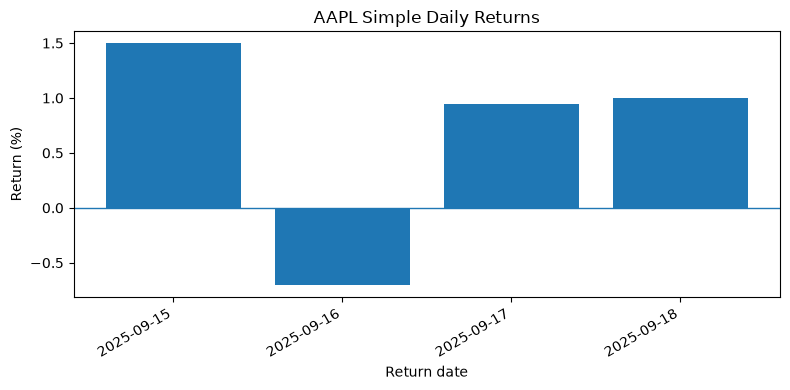

In [5]:
import matplotlib.pyplot as plt

# Use the dates corresponding to the end of each return interval.
return_dates = [date.split(",")[0] for date in rows][1:]

# A compact bar chart makes positive and negative daily returns easy to compare.
plt.figure(figsize=(8, 4))
plt.bar(return_dates, [value * 100 for value in rets])
plt.axhline(0, linewidth=1)
plt.title(f"{ticker} Simple Daily Returns")
plt.xlabel("Return date")
plt.ylabel("Return (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Question 5 — Clean headlines, tokenize, and summarize signals (20 points)

Concepts: lists, Unicode text normalization, regular expressions, `collections.Counter`, sets, and exact membership. The token expression preserves dotted tickers such as `BRK.B` and caret-prefixed indices such as `^GSPC`, while dropping standalone punctuation. The final ticker list is based on exact token matches against `universe`.

In [6]:
headlines = [
    "AAPL gains as Wedbush boosts price-target; BUY reiterated",
    "msft slips after DOJ update; Neutral → HOLD; PT trimmed",
    "GOOG jumps on cloud deal wins—Upgrade to BUY!",
    "NVDA downgraded to HOLD; valuation—stretched?",
    "brk.b: Berkshire raises cash pile—Sell-off in cyclicals?",
    "Spy edges higher; flows strong; BUY-the-dip chatter"
]

signal_buy = {"BUY", "UPGRADE", "ACCUMULATE"}
signal_sell = {"SELL", "DOWNGRADE", "UNDERWEIGHT", "REDUCE"}
signal_hold = {"HOLD", "NEUTRAL", "MARKET PERFORM"}

# Uppercase every headline and standardize common Unicode dash characters to ASCII hyphen.
# Add a space after comma/semicolon/colon when immediately followed by a letter.
# For hyphens, add spacing only when the dash is acting as a separator rather than inside a word
# or ticker (e.g. keep PRICE-TARGET and BUY-THE-DIP intact).
clean_lines = [
    re.sub(r"([,;:])(?=[A-Z])", r"\1 ", re.sub(r"[‐‑‒–—−]", "-", line).upper())
    for line in headlines
]

# Extract tokens consisting only of letters/digits plus periods and carets.
# The expression keeps BRK.B and ^GSPC intact and does not emit standalone punctuation.
tokens = [token for line in clean_lines for token in re.findall(r"\^?[A-Z0-9]+(?:[.-][A-Z0-9]+)*", line)]

# Count standalone BUY, SELL, and HOLD words case-insensitively across the original headlines.
# Counter is allowed by the assignment and word boundaries avoid counting words like BUYBACK.
from collections import Counter
signal_counts = Counter(
    word for line in headlines
    for word in re.findall(r"\b(?:BUY|SELL|HOLD)\b", line, flags=re.IGNORECASE)
)
buy_hits = signal_counts["BUY"]
sell_hits = signal_counts["SELL"]
hold_hits = signal_counts["HOLD"]

# Exact token membership prevents partial matches. A set removes duplicate mentions; sorted() orders them.
mentioned = sorted(set(tokens) & set(universe))

# Format the headline count, signal counts, and comma-joined ticker list exactly as specified.
headline_summary = (
    f"{len(headlines)} headlines | BUY: {buy_hits}, HOLD: {hold_hits}, SELL: {sell_hits} "
    f"| Tickers: {','.join(mentioned)}"
)

print("clean_lines =", clean_lines)
print("tokens =", tokens)
print(f"buy_hits={buy_hits}, sell_hits={sell_hits}, hold_hits={hold_hits}")
print("mentioned =", mentioned)
print("headline_summary =", headline_summary)


clean_lines = ['AAPL GAINS AS WEDBUSH BOOSTS PRICE-TARGET; BUY REITERATED', 'MSFT SLIPS AFTER DOJ UPDATE; NEUTRAL → HOLD; PT TRIMMED', 'GOOG JUMPS ON CLOUD DEAL WINS-UPGRADE TO BUY!', 'NVDA DOWNGRADED TO HOLD; VALUATION-STRETCHED?', 'BRK.B: BERKSHIRE RAISES CASH PILE-SELL-OFF IN CYCLICALS?', 'SPY EDGES HIGHER; FLOWS STRONG; BUY-THE-DIP CHATTER']
tokens = ['AAPL', 'GAINS', 'AS', 'WEDBUSH', 'BOOSTS', 'PRICE-TARGET', 'BUY', 'REITERATED', 'MSFT', 'SLIPS', 'AFTER', 'DOJ', 'UPDATE', 'NEUTRAL', 'HOLD', 'PT', 'TRIMMED', 'GOOG', 'JUMPS', 'ON', 'CLOUD', 'DEAL', 'WINS-UPGRADE', 'TO', 'BUY', 'NVDA', 'DOWNGRADED', 'TO', 'HOLD', 'VALUATION-STRETCHED', 'BRK.B', 'BERKSHIRE', 'RAISES', 'CASH', 'PILE-SELL-OFF', 'IN', 'CYCLICALS', 'SPY', 'EDGES', 'HIGHER', 'FLOWS', 'STRONG', 'BUY-THE-DIP', 'CHATTER']
buy_hits=3, sell_hits=0, hold_hits=2
mentioned = ['AAPL', 'BRK.B', 'GOOG', 'MSFT', 'NVDA', 'SPY']
headline_summary = 6 headlines | BUY: 3, HOLD: 2, SELL: 0 | Tickers: AAPL,BRK.B,GOOG,MSFT,NVDA,SPY


## Final verification checklist

Before submission:
- Run **Kernel → Restart Kernel and Run All Cells** (or the equivalent in your notebook environment).
- Confirm that every cell executes without errors and that the printed outputs match the assignment's sample formatting.
- Keep the assignment's required variable names unchanged.
- Review the comments and be prepared to explain regex character classes, word boundaries (`\b`), list comprehensions, `dict.fromkeys`, set difference/intersection, slicing, `zip`, and percentage formatting.
- The PDF provided by the instructor does not explicitly request a separate PDF submission. The companion PDF generated with this notebook is a study/solution guide, not evidence that a PDF is required by the course.
